Bollinger-bånd er en teknisk indikator for å måle hvor mye kursen på en aksje eller et annet verdipapir svinger. Den består av tre linjer: et midtbånd, som er et glidende gjennomsnitt av kursen (vanligvis over 20 perioder), og et øvre og et nedre bånd som ligger to standardavvik over og under dette gjennomsnittet. Når kursen svinger mye, blir båndene bredere, og når markedet er rolig, trekker de seg sammen. Indikatoren brukes også til å vurdere om et verdipapir er overkjøpt eller oversolgt. Kurs ved eller over det øvre båndet tolkes ofte som at verdipapiret er overkjøpt. Det betyr at kursen har steget mye på kort tid og kan være klar for en nedgang eller en pause. Kurs ved eller under det nedre båndet tolkes tilsvarende som oversolgt, altså at kursen har falt kraftig og kan være klar for et oppsving. Dette er likevel ikke sikre kjøps- eller salgssignaler. I en sterk trend kan kursen bevege seg langs ett av båndene i lang tid, så Bollinger-bånd bør brukes sammen med andre indikatorer, for eksempel RSI eller volum.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

[*********************100%***********************]  1 of 1 completed


Price            Close        High         Low        Open   Volume
Ticker          ORK.OL      ORK.OL      ORK.OL      ORK.OL   ORK.OL
Date                                                               
2020-01-02   62.302551   62.482618   61.568441   61.609993   797789
2020-01-03   62.122490   62.261005   61.609998   62.261005   839410
2020-01-06   61.734653   62.011678   61.332968   61.928569  1147350
2020-01-07   62.247150   62.524175   61.900871   61.970131  1387050
2020-01-08   60.751228   61.706957   60.709677   61.540745  1528284
...                ...         ...         ...         ...      ...
2025-12-19  107.036682  107.606537  106.086933  106.181914  2986764
2025-12-22  105.991959  106.941707  105.896985  106.561806  1184245
2025-12-23  106.371857  107.036678  105.991956  105.991956  1099347
2025-12-29  106.941711  107.321612  106.371864  106.656791   984208
2025-12-30  106.846733  107.511554  106.751760  107.036680  1432495

[1508 rows x 5 columns]


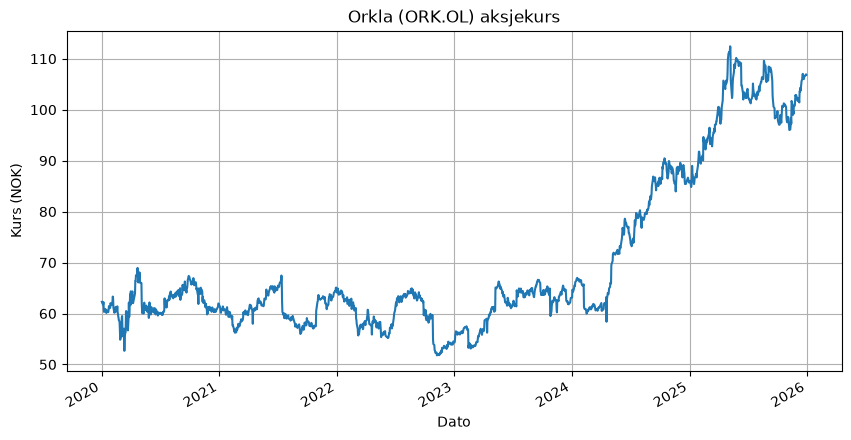

In [3]:
data = yf.download("ORK.OL", start="2020-01-01", end="2026-01-01")
print(data)

data["Close"].plot(figsize=(10, 5), legend=False)
plt.title("Orkla (ORK.OL) aksjekurs")
plt.xlabel("Dato")
plt.ylabel("Kurs (NOK)")
plt.grid(True)
plt.show()

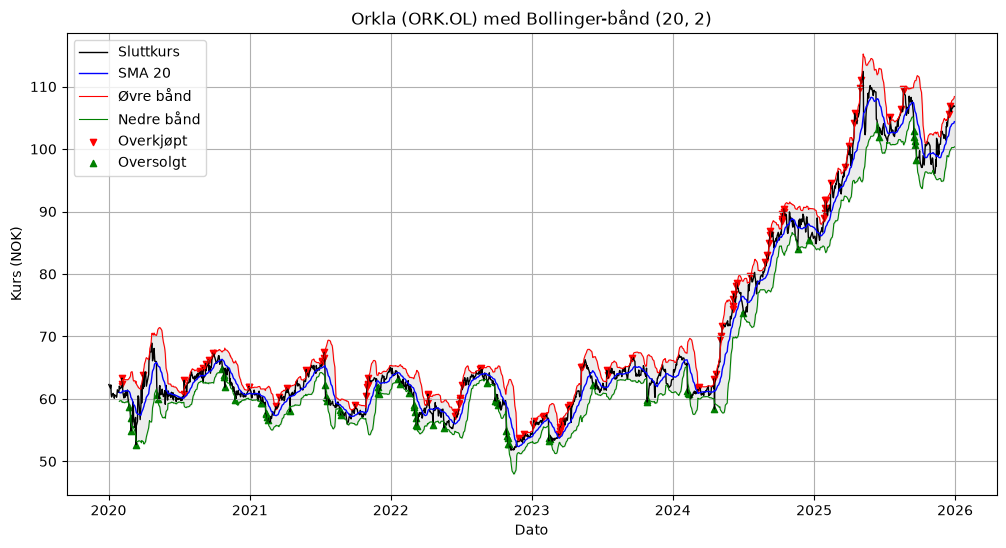

Antall dager overkjøpt: 101
Antall dager oversolgt: 69


In [ ]:
# Bollinger-bånd for Orkla
periode = 20   # antall dager i det glidende gjennomsnittet
antall_std = 2 # antall standardavvik

# Nyere yfinance gir kolonner med to nivåer, squeeze() gjør "Close" om til en vanlig serie
close = data["Close"].squeeze()

bb = pd.DataFrame({"Close": close})
bb["Midt"] = close.rolling(window=periode).mean()
bb["Std"] = close.rolling(window=periode).std()
bb["Øvre"] = bb["Midt"] + antall_std * bb["Std"]
bb["Nedre"] = bb["Midt"] - antall_std * bb["Std"]

# Overkjøpt: kurs over øvre bånd, oversolgt: kurs under nedre bånd
overkjopt = bb[bb["Close"] > bb["Øvre"]]
oversolgt = bb[bb["Close"] < bb["Nedre"]]

plt.figure(figsize=(12, 6))
plt.plot(bb.index, bb["Close"], label="Sluttkurs", color="black", linewidth=1)
plt.plot(bb.index, bb["Midt"], label=f"SMA {periode}", color="blue", linewidth=1)
plt.plot(bb.index, bb["Øvre"], label="Øvre bånd", color="red", linewidth=0.8)
plt.plot(bb.index, bb["Nedre"], label="Nedre bånd", color="green", linewidth=0.8)
plt.fill_between(bb.index, bb["Nedre"], bb["Øvre"], color="grey", alpha=0.15)

plt.title("Orkla (ORK.OL) med Bollinger-bånd (20, 2)")
plt.xlabel("Dato")
plt.ylabel("Kurs (NOK)")
plt.legend()
plt.grid(True)
plt.show()

print(f"Antall dager overkjøpt: {len(overkjopt)}")
print(f"Antall dager oversolgt: {len(oversolgt)}")

Veldig vanskelig å lese av når intervallet er så stort så under er ett intevall for bare 2025



Svart linje (sluttkurs): Det Orkla-aksjen faktisk kostet ved børsens stengning hver dag. Dette er selve aksjekursen. I begynnelsen av januar var den rundt 86 kroner.

Blå linje (SMA 20): Gjennomsnittet av de siste 20 dagenes sluttkurser. Den er en utjevnet versjon av den svarte linjen og viser trenden. Ligger den svarte linjen over den blå, er kursen høyere enn den har vært i snitt den siste måneden. Ligger den under, er den lavere.

Rød linje (øvre bånd): «Taket», altså hvor høyt kursen normalt går. Den ligger over den blå linjen, og avstanden avhenger av hvor mye kursen har svingt. Kommer den svarte linjen helt opp til den røde, har kursen steget uvanlig mye på kort tid. Det kalles overkjøpt.

Grønn linje (nedre bånd): «Gulvet», altså hvor lavt kursen normalt går. Kommer den svarte linjen helt ned til den grønne, har kursen falt uvanlig mye på kort tid. Det kalles oversolgt.

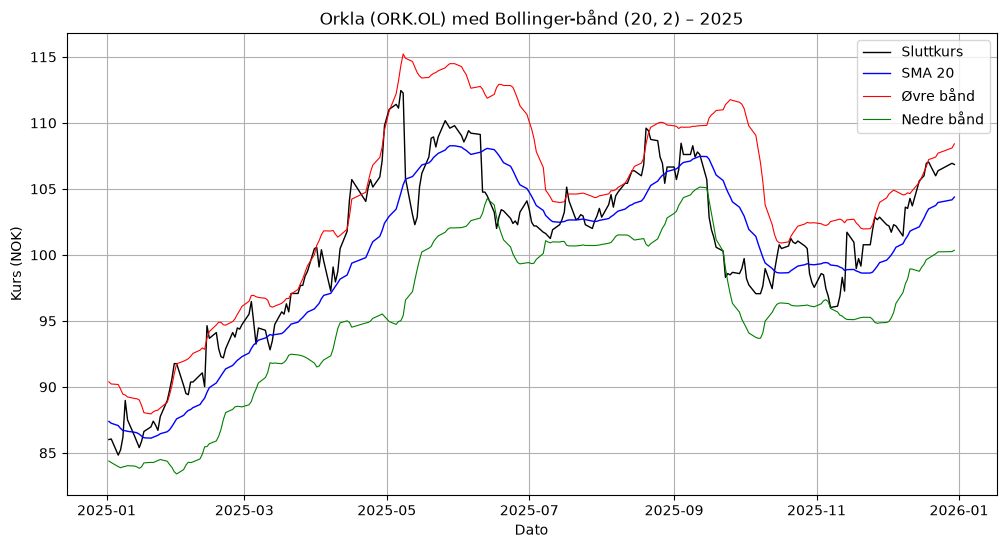

Antall dager overkjøpt i 2025: 18
Antall dager oversolgt i 2025: 7


In [7]:
# Bollinger-bånd for Orkla
periode = 20   # antall dager i det glidende gjennomsnittet
antall_std = 2 # antall standardavvik

# Nyere yfinance gir kolonner med to nivåer, squeeze() gjør "Close" om til en vanlig serie
close = data["Close"].squeeze()

bb = pd.DataFrame({"Close": close})
bb["Midt"] = close.rolling(window=periode).mean()
bb["Std"] = close.rolling(window=periode).std()
bb["Øvre"] = bb["Midt"] + antall_std * bb["Std"]
bb["Nedre"] = bb["Midt"] - antall_std * bb["Std"]

# Bare år 2025 (båndene er regnet ut over, så de er riktige fra 2. januar)
bb = bb.loc["2025-01-01":"2025-12-31"]

# Overkjøpt: kurs over øvre bånd, oversolgt: kurs under nedre bånd
overkjopt = bb[bb["Close"] > bb["Øvre"]]
oversolgt = bb[bb["Close"] < bb["Nedre"]]

plt.figure(figsize=(12, 6))
plt.plot(bb.index, bb["Close"], label="Sluttkurs", color="black", linewidth=1)
plt.plot(bb.index, bb["Midt"], label=f"SMA {periode}", color="blue", linewidth=1)
plt.plot(bb.index, bb["Øvre"], label="Øvre bånd", color="red", linewidth=0.8)
plt.plot(bb.index, bb["Nedre"], label="Nedre bånd", color="green", linewidth=0.8)


plt.title("Orkla (ORK.OL) med Bollinger-bånd (20, 2) – 2025")
plt.xlabel("Dato")
plt.ylabel("Kurs (NOK)")
plt.legend()
plt.grid(True)
plt.show()

print(f"Antall dager overkjøpt i 2025: {len(overkjopt)}")
print(f"Antall dager oversolgt i 2025: {len(oversolgt)}")

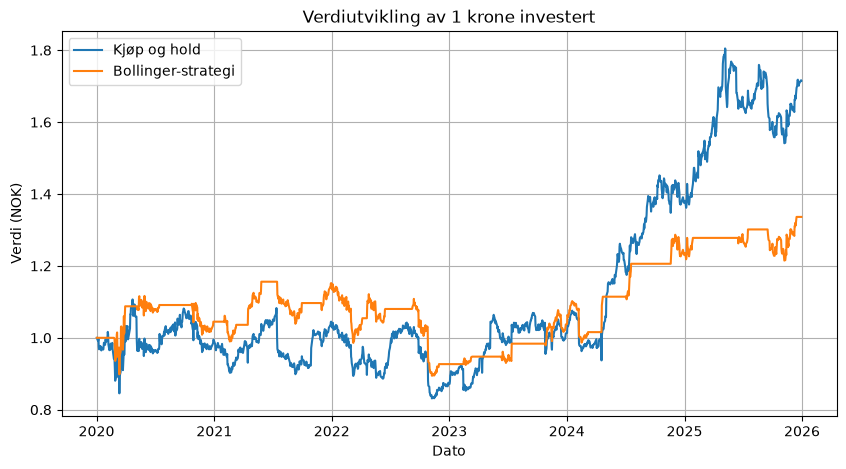

Kjøp og hold:  71.5 % avkastning
Bollinger-strategi:  33.6 % avkastning
Andel av tiden i markedet: 46.4 %


In [9]:
# Bollinger-strategi vs. kjøp og hold
periode = 20
antall_std = 2

close = data["Close"].squeeze()
bt = pd.DataFrame({"Close": close})
bt["Midt"] = close.rolling(periode).mean()
std = close.rolling(periode).std()
bt["Øvre"] = bt["Midt"] + antall_std * std
bt["Nedre"] = bt["Midt"] - antall_std * std

# Kjøp når kursen lukker under nedre bånd, selg når den lukker over øvre bånd
bt["Signal"] = float("nan")
bt.loc[bt["Close"] < bt["Nedre"], "Signal"] = 1
bt.loc[bt["Close"] > bt["Øvre"], "Signal"] = 0
bt["Signal"] = bt["Signal"].ffill().fillna(0)

# Handler dagen etter signalet
bt["Posisjon"] = bt["Signal"].shift(1).fillna(0)

bt["Avkastning"] = bt["Close"].pct_change().fillna(0)
bt["Strategi"] = bt["Posisjon"] * bt["Avkastning"]

bt["Kjøp og hold"] = (1 + bt["Avkastning"]).cumprod()
bt["Bollinger-strategi"] = (1 + bt["Strategi"]).cumprod()

plt.figure(figsize=(10, 5))
plt.plot(bt.index, bt["Kjøp og hold"], label="Kjøp og hold")
plt.plot(bt.index, bt["Bollinger-strategi"], label="Bollinger-strategi")
plt.title("Verdiutvikling av 1 krone investert")
plt.xlabel("Dato")
plt.ylabel("Verdi (NOK)")
plt.legend()
plt.grid(True)
plt.show()

print(f"Kjøp og hold:  {(bt['Kjøp og hold'].iloc[-1] - 1) * 100:.1f} % avkastning")
print(f"Bollinger-strategi:  {(bt['Bollinger-strategi'].iloc[-1] - 1) * 100:.1f} % avkastning")
print(f"Andel av tiden i markedet: {bt['Posisjon'].mean() * 100:.1f} %")

2020–2023: sidelengs marked, der strategien var best
Kursen svingte opp og ned rundt samme nivå i fire år. Her er Bollinger-strategien laget for å fungere. Den kjøpte når kursen hadde falt mye og solgte når den hadde steget mye, og lå foran kjøp og hold nesten hele tiden. Den falt også mindre i dårlige perioder. Bunnen i slutten av 2022 var rundt 0,90 for strategien mot rundt 0,83 for kjøp og hold.

2024–2025: sterk oppgang, der strategien tapte
Da Orkla begynte å stige jevnt fra våren 2024, solgte strategien hver gang kursen traff det øvre båndet. Etterpå ventet den på at kursen skulle falle ned til det nedre båndet før den kjøpte igjen. I en sterk oppgang skjer det sjelden. De flate oransje strekene betyr at strategien sto i kontanter mens aksjen steg fra 1,1 til 1,8.